# 03 · Transfer Learning and Architectures
**Course Modules 2 (Transfer learning) and 3 (Advanced architectures)**

**Strategy:** notebook 02 showed that a small network trained from zero on lab photos does not work in the field.
Networks pretrained on millions of varied photos (ImageNet: 1.2 M images, 1,000 classes) already know edges, textures, shapes and lighting.
We **reuse** that knowledge and compare two ways of doing so, across four architectures, judged on **field accuracy, size and speed**, not lab accuracy.

| Experiment | What is trained | Question it answers |
|---|---|---|
| Linear probe | only the last layer; the backbone is frozen | Are the pretrained features good enough as they are? |
| Fine-tuning | all layers, small learning rate | How much does adapting the whole network help? |
| Architecture comparison | MobileNetV3, EfficientNet-B0, ResNet-50, DINOv2 ViT-S | Which design transfers best to the field, at what cost? |
| Field track | fine-tune with some PlantDoc *train* photos added | What if we can collect a few real field photos? |

In [1]:
import time, torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
from lab_to_field.config import N_CLASSES, FIGURES_DIR
from lab_to_field.models import build_model, count_params
from lab_to_field.train import TrainConfig, load_results
from lab_to_field.experiment import run
plt.rcParams["figure.dpi"] = 110

## 1. Transfer learning, in simple words

A pretrained network has two parts:
- the **backbone**: layers that turn pixels into a feature vector (general visual knowledge)
- the **head**: the last layer, mapping features to classes (ImageNet's 1,000 classes)

We replace the head with a new 28-class layer. Then:

| | Linear probe (feature extraction) | Fine-tuning |
|---|---|---|
| Trained | only the new head | head + backbone |
| Trainable parameters | tiny (~36 k) | millions |
| Learning rate | larger (1e-2 to 3e-3) | small (1e-3 or less), so pretrained knowledge is not destroyed |
| Risk | features may not fit our task | overfitting to lab photos: the model may *forget* general knowledge and learn lab shortcuts |

The second risk is the interesting one for us: fine-tuning gets better *lab* scores, but does it get better *field* scores?

## 2. The architectures (Module 3)

| Model | Key idea | Params |
|---|---|---|
| **ResNet-50** (2015) | **Residual connections**: each block learns `x + F(x)`, so very deep networks can be trained | 25.6 M |
| **MobileNetV3-Large** (2019) | **Depthwise separable convs** (filter each channel alone, then mix with 1×1), **squeeze-and-excitation** (channel attention), **hard-swish** activation. Designed for phones | 5.5 M |
| **EfficientNet-B0** (2019) | Same mobile blocks, with depth, width and resolution **scaled together** ("compound scaling") | 5.3 M |
| **DINOv2 ViT-S/14** (2023) | **Vision Transformer**: cuts the image into 14×14 patches and uses self-attention. Pretrained **without labels** on 142 M images (self-supervised) | 22 M |

**Why depthwise separable convs are cheap**, for a 3×3 conv from 128 to 128 channels:
- normal conv: 3·3·128·128 = **147,456** weights
- depthwise (3·3·128 = 1,152) + pointwise 1×1 (128·128 = 16,384) = **17,536** weights, **8.4× fewer**

In [2]:
# Size and CPU speed of each architecture (batch of 1, like a phone app)
archs = {"simple_cnn": {}, "mobilenetv3_large_100": {}, "efficientnet_b0": {}, "resnet50": {},
         "vit_small_patch14_dinov2.lvd142m": {"img_size": 224}}
rows = []
torch.set_num_threads(4)  # roughly a phone/laptop CPU budget
for name, kw in archs.items():
    m = build_model(name, N_CLASSES, pretrained=False, **kw).eval()
    x = torch.randn(1, 3, 224, 224)
    with torch.inference_mode():
        for _ in range(3): m(x)
        t = time.perf_counter()
        for _ in range(10): m(x)
    rows.append({"model": name.split(".")[0], "params (M)": count_params(m)[0] / 1e6,
                 "size fp32 (MB)": count_params(m)[0] * 4 / 1e6, "CPU ms / image": (time.perf_counter() - t) / 10 * 1000})
arch_table = pd.DataFrame(rows).round(1)
arch_table

,model,params (M),size fp32 (MB),CPU ms / image
0,simple_cnn,0.4,1.6,11.3
1,mobilenetv3_large_100,4.2,17.0,7.3
2,efficientnet_b0,4.0,16.2,15.4
3,resnet50,23.6,94.3,38.1
4,vit_small_patch14_dinov2,21.6,86.6,43.7


## 3. Run the experiments
All runs use the same data, augmentation (`basic`) and recipe, so the **only** thing that changes is the model or what is trained. That is a *controlled* comparison.

In [3]:
experiments = [
    TrainConfig(name="03_mnv3_probe", model="mobilenetv3_large_100", freeze_backbone=True, lr=3e-3, epochs=5),
    TrainConfig(name="03_mnv3_finetune", model="mobilenetv3_large_100", lr=1e-3, epochs=6),
    TrainConfig(name="03_effb0_finetune", model="efficientnet_b0", lr=1e-3, epochs=6),
    TrainConfig(name="03_resnet50_finetune", model="resnet50", lr=5e-4, epochs=5, batch_size=48),
    TrainConfig(name="03_dinov2_probe", model="vit_small_patch14_dinov2.lvd142m", freeze_backbone=True,
                lr=3e-3, epochs=5, extra={"model_kwargs": {"img_size": 224}}),
]
for cfg in experiments:
    run(cfg, track="lab")

[03_mnv3_probe] loaded saved result (delete 03_mnv3_probe.json or pass force=True to retrain): lab acc 0.958 | field val 0.237 | field test 0.271
[03_mnv3_finetune] loaded saved result (delete 03_mnv3_finetune.json or pass force=True to retrain): lab acc 0.989 | field val 0.180 | field test 0.301
[03_effb0_finetune] loaded saved result (delete 03_effb0_finetune.json or pass force=True to retrain): lab acc 0.991 | field val 0.186 | field test 0.250
[03_resnet50_finetune] loaded saved result (delete 03_resnet50_finetune.json or pass force=True to retrain): lab acc 0.989 | field val 0.191 | field test 0.322
[03_dinov2_probe] loaded saved result (delete 03_dinov2_probe.json or pass force=True to retrain): lab acc 0.976 | field val 0.429 | field test 0.462


### Field track: what if we collect a few real field photos?
Same MobileNetV3 fine-tuning, but PlantDoc *train* photos (~1,900) are added to training, and the best epoch is chosen on PlantDoc *validation*. PlantDoc *test* stays untouched.

In [4]:
run(TrainConfig(name="03_mnv3_finetune_field", model="mobilenetv3_large_100", lr=1e-3, epochs=6), track="field")

[03_mnv3_finetune_field] loaded saved result (delete 03_mnv3_finetune_field.json or pass force=True to retrain): lab acc 0.991 | field val 0.671 | field test 0.644


{'config': {'name': '03_mnv3_finetune_field',
  'model': 'mobilenetv3_large_100',
  'epochs': 6,
  'lr': 0.001,
  'weight_decay': 0.0001,
  'optimizer': 'adamw',
  'loss': 'ce',
  'batch_size': 64,
  'img_size': 224,
  'augment': 'basic',
  'freeze_backbone': False,
  'act': 'relu',
  'seed': 0,
  'extra': {}},
 'history': [{'epoch': 1,
   'train_loss': 0.8795246079825518,
   'val_acc': 0.5942857142857143},
  {'epoch': 2, 'train_loss': 0.22264580722048619, 'val_acc': 0.62},
  {'epoch': 3,
   'train_loss': 0.09966476979224305,
   'val_acc': 0.6485714285714286},
  {'epoch': 4,
   'train_loss': 0.04653966509197888,
   'val_acc': 0.6685714285714286},
  {'epoch': 5,
   'train_loss': 0.020370043435117655,
   'val_acc': 0.6714285714285714},
  {'epoch': 6,
   'train_loss': 0.015220688584080913,
   'val_acc': 0.6657142857142857}],
 'best_val_acc': 0.6714285714285714,
 'train_minutes': 2.7142387509346007,
 'track': 'field',
 'params_total': 4237900,
 'params_trainable': 4237900,
 'n_train': 1827

In [5]:
R = load_results()
names = ["02_simple_cnn", "03_mnv3_probe", "03_mnv3_finetune", "03_effb0_finetune", "03_resnet50_finetune",
         "03_dinov2_probe", "03_mnv3_finetune_field"]
tbl = pd.DataFrame([{
    "experiment": n, "track": R[n]["track"],
    "trainable params (M)": R[n]["params_trainable"] / 1e6,
    "lab acc": R[n]["lab_test"]["accuracy"], "field acc": R[n]["field_test"]["accuracy"],
    "field 95% CI": "{:.1%}–{:.1%}".format(*R[n]["field_test"]["accuracy_ci95"]),
    "field macro-F1": R[n]["field_test"]["macro_f1"], "field ECE": R[n]["field_test"]["ece"],
    "minutes": R[n]["train_minutes"]} for n in names if n in R])
tbl.round(3)

,experiment,track,trainable params (M),lab acc,field acc,field 95% CI,field macro-F1,field ECE,minutes
0,02_simple_cnn,lab,0.396,0.958,0.089,5.5%–12.7%,0.079,0.690,3.592
1,03_mnv3_probe,lab,0.036,0.958,0.271,21.6%–32.6%,0.266,0.382,0.783
2,03_mnv3_finetune,lab,4.238,0.989,0.301,24.2%–36.4%,0.264,0.515,1.939
3,03_effb0_finetune,lab,4.043,0.991,0.250,19.9%–30.9%,0.229,0.474,3.545
4,03_resnet50_finetune,lab,23.565,0.989,0.322,26.7%–38.6%,0.296,0.409,4.736
5,03_dinov2_probe,lab,0.011,0.976,0.462,39.8%–52.5%,0.458,0.328,2.102
6,03_mnv3_finetune_field,field,4.238,0.991,0.644,58.5%–70.3%,0.637,0.227,2.714


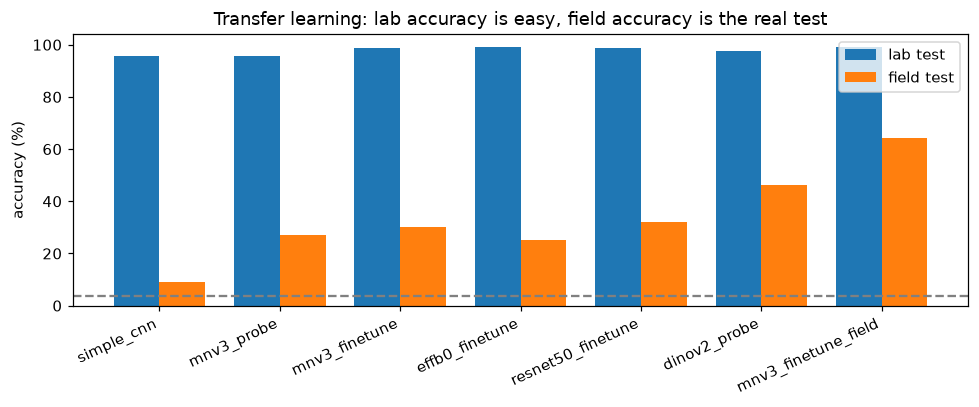

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(tbl)); w = .38
ax.bar(x - w / 2, tbl["lab acc"] * 100, w, label="lab test")
ax.bar(x + w / 2, tbl["field acc"] * 100, w, label="field test")
ax.set_xticks(x, [n.replace("03_", "").replace("02_", "") for n in tbl.experiment], rotation=25, ha="right")
ax.axhline(100 / N_CLASSES, ls="--", c="grey"); ax.set_ylabel("accuracy (%)"); ax.legend()
ax.set_title("Transfer learning: lab accuracy is easy, field accuracy is the real test")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "03_transfer.png", bbox_inches="tight")

## 4. How to read the results

Look at the **field acc** column, not lab acc. Lab accuracy is high for almost every model and tells us little.

Questions to answer from the table :
1. **Pretrained vs scratch:** how many points does ImageNet pretraining add *in the field* compared with notebook 02?
2. **Probe vs fine-tune:** fine-tuning usually wins in the lab. Does it also win in the field, or does it overfit to lab shortcuts?
3. **DINOv2 (self-supervised ViT):** published work (Xiang et al. 2026) found frozen DINOv2 features much more robust to the lab-to-field shift than a fine-tuned ResNet-50. Do we see the same?
4. **Field track:** how much do ~1,900 real photos add? This is the strongest argument for collecting field data (for example Punjab phone photos).
5. **Cost:** is a big model's field gain worth its size and latency on a phone? (See `arch_table`.)

**Decision for the next notebooks:** we keep **MobileNetV3-Large** as the main model. It is phone-sized (5.5 M params, ~20 MB, fast on CPU), so every improvement we find in notebooks 04 and 05 is one we can actually ship.

### Our results
| Model | Trained | Lab acc | Field acc (95% CI) | Field ECE |
|---|---|---|---|---|
| Scratch CNN (nb 02) | all | 95.8% | 8.9% | 0.69 |
| MobileNetV3 | head only (probe) | 95.8% | 27.1% | 0.38 |
| MobileNetV3 | all (fine-tune) | 98.9% | 30.1% | 0.52 |
| EfficientNet-B0 | all | 99.1% | 25.0% | 0.47 |
| ResNet-50 | all | 98.9% | 32.2% | 0.41 |
| **DINOv2 ViT-S** | head only | 97.6% | **46.2%** (40–53%) | 0.33 |
| MobileNetV3 + field photos | all | 99.1% | **64.4%** (58–70%) | 0.23 |

1. **Pretraining is the biggest single step:** 8.9% → 25–32% in the field, for every pretrained CNN.
2. **Lab accuracy does not predict field accuracy:** EfficientNet-B0 has the *best* lab score and the *worst* field score among the fine-tuned CNNs.
3. **Fine-tuning vs probe:** fine-tuning adds ~3 points in the field (within noise) but makes the model *more overconfident* (ECE 0.38 → 0.52). It learns the lab more, not the world more.
4. **Self-supervised features transfer best:** frozen DINOv2 beats every fine-tuned CNN by 14+ points. Our ResNet-50 (32.2%) and DINOv2 (46.2%) numbers match the published 32.05% and ~41–43% (Xiang et al. 2026), a sign our pipeline is sound.
5. **Real field photos matter most:** adding ~2,000 PlantDoc photos lifts MobileNetV3 from 30.1% to 64.4%, in the published 65–72% range for this setting.

**Why we still deploy MobileNetV3 and not DINOv2:** DINOv2 is 4× larger and much slower on a CPU. A distilled version (DINOv2 teaching MobileNetV3) is a planned next step.

## Review questions
1. What is the difference between a linear probe and fine-tuning? When would you choose each?
2. Why use a smaller learning rate for fine-tuning than for training from scratch?
3. How does a residual connection help a very deep network train?
4. Compute the weights of a normal 3×3 conv vs a depthwise separable conv for 64 → 64 channels.
5. What is self-supervised pretraining, and why might it generalise better than ImageNet labels?
6. Why do we pick the final model on field accuracy *and* phone cost, not lab accuracy?